# Plastic pyrolysis oil yield - real data (Belden 2023), audited

Oil-yield regression on the real 325-row Belden et al. (2023) dataset (39 papers).
This version takes the data seriously: it audits the CSV, evaluates **honestly**
(grouped by source paper to avoid leakage), handles missing values without
inventing them, and returns **several** recommendations with their uncertainty.

Headline from the audit: random cross-validation reports ~9 % MAE (matching the
paper), but that is optimistic - rows from the same paper leak across folds.
Grouping by paper, the honest MAE roughly doubles. That gap is the real story.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap, joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA_DIR = Path("data") if Path("data").exists() else Path("../data")
MODEL_DIR = Path("models") if Path("models").exists() else Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (7, 4)

## 2. Load

In [2]:
df = pd.read_csv(DATA_DIR / "reference" / "belden2023_oilyield.csv")
FRACTION_COLS = ["HDPE_wt", "LDPE_wt", "PP_wt", "PS_wt", "PVC_wt", "PET_wt"]
COND_NUM = ["temperature_C", "heating_rate_C_min", "particle_size_mm", "feed_mass_g"]
print("shape:", df.shape, "| papers:", df.source_ref.nunique())
df.head()

shape: (325, 15) | papers: 39


,HDPE_wt,LDPE_wt,PP_wt,PS_wt,PVC_wt,PET_wt,plastic_sum_wt,temperature_C,heating_rate_C_min,particle_size_mm,feed_mass_g,catalyst,reactor_type,oil_yield_wpct,source_ref
0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,500.0,10.0,2.5,NaN,No,Fixed Bed,95.0,1
1,0.0,100.0,0.0,0.0,0.0,0.0,100.0,400.0,10.0,2.5,NaN,Yes,Fixed Bed,84.0,1
2,0.0,100.0,0.0,0.0,0.0,0.0,100.0,450.0,10.0,2.5,NaN,Yes,Fixed Bed,81.0,1
3,0.0,100.0,0.0,0.0,0.0,0.0,100.0,500.0,10.0,2.5,NaN,Yes,Fixed Bed,80.0,1
4,0.0,100.0,0.0,0.0,0.0,0.0,100.0,550.0,10.0,2.5,NaN,Yes,Fixed Bed,76.0,1


## 3. Data audit

Before modelling, check whether the data can carry the weight we want to put on
it. Four lenses: how concentrated the data is per paper (leakage risk), physical
plausibility, duplicates/contradictions, and the pattern of missing values.

In [3]:
# --- per-paper concentration (leakage risk) ---
vc = df.source_ref.value_counts()
print("rows/paper: median %.0f, max %d (%.0f%% of data); top-5 papers = %.0f%%"
      % (vc.median(), vc.max(), 100*vc.max()/len(df), 100*vc.head(5).sum()/len(df)))

# --- physical plausibility ---
print("\noil yield outside [0,100]:", int(((df.oil_yield_wpct<0)|(df.oil_yield_wpct>100)).sum()))
big = df.particle_size_mm >= 50
print("particle_size >= 50 mm (implausible 'particle'):", int(big.sum()),
      "-> only papers", sorted(df.loc[big, "source_ref"].unique()))
psum = df[FRACTION_COLS].sum(axis=1)
print("plastic fractions sum range: %.1f - %.1f (rows <95 = mixed w/ non-plastic: %d)"
      % (psum.min(), psum.max(), int((psum<95).sum())))

# --- duplicates / contradictions ---
key = FRACTION_COLS + COND_NUM + ["catalyst", "reactor_type"]
spread = df[df.duplicated(key, keep=False)].groupby(key, dropna=False)["oil_yield_wpct"].agg(lambda s: s.max()-s.min())
print("\nexact duplicate rows:", int(df.duplicated().sum()))
print("identical-condition groups with >10 pt yield spread:", int((spread>10).sum()),
      "(worst: %.0f pts) -> hidden variables (e.g. residence time, not a column)" % spread.max())

rows/paper: median 7, max 24 (7% of data); top-5 papers = 30%

oil yield outside [0,100]: 0
particle_size >= 50 mm (implausible 'particle'): 21 -> only papers [np.int64(30), np.int64(39)]
plastic fractions sum range: 54.7 - 101.0 (rows <95 = mixed w/ non-plastic: 10)

exact duplicate rows: 1
identical-condition groups with >10 pt yield spread: 11 (worst: 43 pts) -> hidden variables (e.g. residence time, not a column)


In [4]:
# --- missingness: is it random, or tied to paper / reactor? ---
rows = []
for c in COND_NUM:
    by_paper = df.groupby("source_ref")[c].apply(lambda s: s.isna().all()).sum()
    by_reactor = df.groupby("reactor_type")[c].apply(lambda s: s.isna().mean())
    rows.append({"feature": c, "missing_%": round(100*df[c].isna().mean()),
                 "papers_100%_missing": f"{by_paper}/{df.source_ref.nunique()}",
                 "fluidized_vs_fixed": f"{by_reactor.get('Fluidized Bed',0)*100:.0f}% vs {by_reactor.get('Fixed Bed',0)*100:.0f}%"})
print(pd.DataFrame(rows).to_string(index=False))
print("\nMissingness is NOT random: it is concentrated by paper and reactor type")
print("(MNAR). Median imputation would inject reactor-correlated fake values, so")
print("below we keep NaN, use models that handle it natively, and flag it instead.")

           feature  missing_% papers_100%_missing fluidized_vs_fixed
     temperature_C          0                0/39           0% vs 0%
heating_rate_C_min         20                9/39          62% vs 2%
  particle_size_mm         28               13/39         26% vs 26%
       feed_mass_g         27               11/39         86% vs 52%

Missingness is NOT random: it is concentrated by paper and reactor type
(MNAR). Median imputation would inject reactor-correlated fake values, so
below we keep NaN, use models that handle it natively, and flag it instead.


## 4. Features: keep missing as missing, flag it

Numeric features pass through with their NaNs intact (the models below handle
missing natively). For the three partly-missing conditions we add a `*_missing`
indicator, so the model can use the fact that a value was not reported - which,
given the MNAR pattern, is itself informative.

In [5]:
MISS_FLAGS = [c + "_missing" for c in ["heating_rate_C_min", "particle_size_mm", "feed_mass_g"]]
for c in ["heating_rate_C_min", "particle_size_mm", "feed_mass_g"]:
    df[c + "_missing"] = df[c].isna().astype(int)

NUM_FEATURES = FRACTION_COLS + COND_NUM + MISS_FLAGS
CAT_FEATURES = ["catalyst", "reactor_type"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "oil_yield_wpct"
X, y, groups = df[FEATURES].copy(), df[TARGET].copy(), df["source_ref"]

def make_preprocessor():   # no imputation: NaN passes through to the model
    return ColumnTransformer([
        ("num", "passthrough", NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])

## 5. Honest evaluation: random CV vs grouped-by-paper CV

All three models handle NaN natively (no invented values). We score each with
ordinary random 5-fold CV and with GroupKFold that keeps each paper entirely in
one fold. The grouped number is the honest estimate of how well this predicts a
*new* study.

In [6]:
def make_models():
    return {
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                                subsample=0.9, colsample_bytree=0.9,
                                random_state=RANDOM_STATE, verbosity=0),
        "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                                  num_leaves=15, min_child_samples=5,
                                  random_state=RANDOM_STATE, verbose=-1),
        "HistGBR": HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05,
                                                 random_state=RANDOM_STATE),
    }

random_cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
group_cv = GroupKFold(5)
rows, oof_group = [], {}
for name, model in make_models().items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pr = cross_val_predict(pipe, X, y, cv=random_cv)
    pg = cross_val_predict(pipe, X, y, cv=group_cv, groups=groups)
    oof_group[name] = pg
    rows.append({"model": name,
                 "R2_random": r2_score(y, pr), "MAE_random": mean_absolute_error(y, pr),
                 "R2_grouped": r2_score(y, pg), "MAE_grouped": mean_absolute_error(y, pg)})
results = pd.DataFrame(rows).sort_values("MAE_grouped").reset_index(drop=True)
print(results.round(2).to_string(index=False))
print("\nThe R2_random -> R2_grouped drop is the optimism from paper leakage.")

   model  R2_random  MAE_random  R2_grouped  MAE_grouped
 XGBoost       0.71        8.50        0.21        16.77
LightGBM       0.73        8.55        0.02        17.64
 HistGBR       0.64       10.61        0.08        18.09

The R2_random -> R2_grouped drop is the optimism from paper leakage.


## 6. Fit the honest-best model, parity plot (grouped out-of-fold)

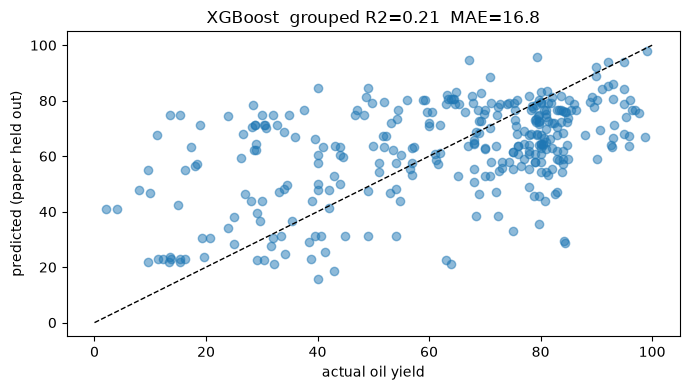

In [7]:
best_name = results.iloc[0]["model"]
final_model = Pipeline([("prep", make_preprocessor()), ("model", make_models()[best_name])])
final_model.fit(X, y)
oof_best = oof_group[best_name]      # honest, paper-held-out predictions

plt.scatter(y, oof_best, alpha=0.5)
lims = [0, 100]; plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("actual oil yield"); plt.ylabel("predicted (paper held out)")
plt.title(f"{best_name}  grouped R2={r2_score(y,oof_best):.2f}  MAE={mean_absolute_error(y,oof_best):.1f}")
plt.tight_layout(); plt.show()

## 7. Outliers vs mistakes

The largest errors under grouped CV are not random - they cluster in a few
papers that explore regimes nobody else did (very low yields, or very high
temperatures). Those are *outliers* the model cannot reach when their paper is
held out, not necessarily transcription *mistakes*. A per-paper error table is
the source check that tells them apart.

In [8]:
d2 = df.assign(pred=oof_best.round(1), abs_err=(y-oof_best).abs())
print("worst-predicted papers (grouped CV):")
print(d2.groupby("source_ref").agg(n=("abs_err","size"), mean_abs_err=("abs_err","mean"))
        .round(1).sort_values("mean_abs_err", ascending=False).head(6).to_string())
print("\ntop mispredicted rows (check these against the source papers):")
print(d2.nlargest(5,"abs_err")[["source_ref","temperature_C","catalyst","reactor_type","oil_yield_wpct","pred"]].to_string(index=False))

worst-predicted papers (grouped CV):
             n  mean_abs_err
source_ref                  
31           8          42.6
11           7          35.2
39          13          34.4
23           5          29.9
7            4          28.9
9            4          26.0

top mispredicted rows (check these against the source papers):
 source_ref  temperature_C catalyst    reactor_type  oil_yield_wpct      pred
         12          450.0       No Horizontal Tube           13.61 75.000000
         12          450.0       No Horizontal Tube           15.40 74.699997
          7          400.0       No           Batch           11.20 67.800003
         11          700.0       No       Fixed Bed           84.44 28.700001
         11          700.0       No       Fixed Bed           84.25 29.400000


## 8. Which conditions matter? (SHAP)

Feature importance for the oil-yield model, including the `*_missing` flags -
if a flag ranks highly, missingness itself is carrying signal (a data-quality
tell, not real physics).

/var/folders/m5/rnwzbv2s35x737bggbrtnksc0000gp/T/ipykernel_96029/4637771.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_trans, feature_names=feat_names, show=True)


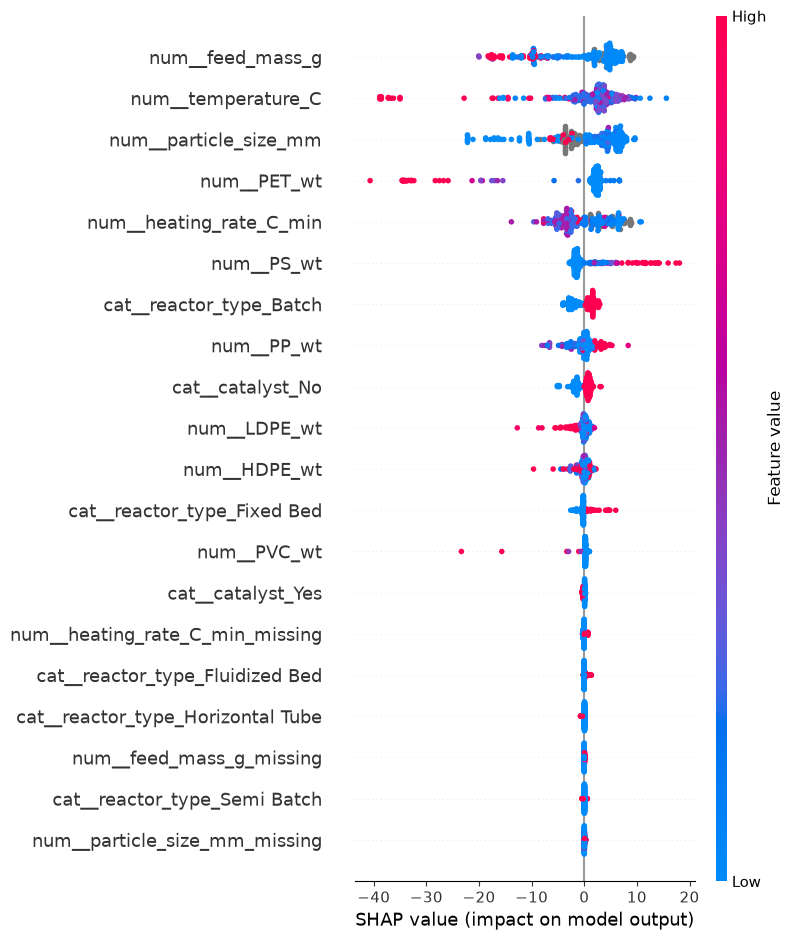

In [9]:
prep = final_model.named_steps["prep"]; model = final_model.named_steps["model"]
X_trans = prep.transform(X); feat_names = prep.get_feature_names_out()
try:
    sv = shap.TreeExplainer(model).shap_values(X_trans)
except Exception:
    sv = shap.Explainer(model, X_trans)(X_trans).values
shap.summary_plot(sv, X_trans, feature_names=feat_names, show=True)

## 9. Trust: conformal interval (from grouped residuals) + in-domain flag

The conformal band uses the **grouped** out-of-fold residuals, so it reflects
honest new-paper error and comes out appropriately wide. The applicability-domain
check flags conditions far from the training data. (For the distance only, we
median-impute + scale - a heuristic, not a model input.)

In [10]:
ALPHA = 0.10
resid = np.abs(y.values - oof_best)
qhat = float(np.quantile(resid, 1 - ALPHA))
print(f"90% conformal half-width (grouped): +/- {qhat:.1f} wt%   coverage {np.mean(resid<=qhat):.2f}")

ad_prep = Pipeline([("prep", ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)])),
          ("scale", StandardScaler())])
X_ad = ad_prep.fit_transform(X)
ad_nn = NearestNeighbors(n_neighbors=6).fit(X_ad)
AD_THRESHOLD = float(np.quantile(ad_nn.kneighbors(X_ad)[0][:,1:].mean(1), 0.95))

def domain_score(conditions: dict):
    row = pd.DataFrame([conditions]).reindex(columns=FEATURES)
    d = ad_nn.kneighbors(ad_prep.transform(row))[0][0][:5].mean()
    return float(d), bool(d <= AD_THRESHOLD)
print(f"in-domain threshold: {AD_THRESHOLD:.2f}")

90% conformal half-width (grouped): +/- 37.0 wt%   coverage 0.90
in-domain threshold: 2.98


## 10. Trust-aware prediction

In [11]:
def _fill(conditions: dict) -> dict:
    """Default any unspecified feature (fractions 0, flags 0, conditions NaN)."""
    row = {c: 0.0 for c in FRACTION_COLS} | {c: 0 for c in MISS_FLAGS}
    row |= {c: np.nan for c in COND_NUM} | {"catalyst": "No", "reactor_type": "Fixed Bed"}
    row.update(conditions)
    return row

def predict_oil(conditions: dict) -> dict:
    row = pd.DataFrame([_fill(conditions)])[FEATURES]
    point = float(final_model.predict(row)[0])
    score, in_dom = domain_score(_fill(conditions))
    return {"oil_yield_pct": round(point,1), "band_wpct": round(qhat,1),
            "in_domain": in_dom, "ad_score": round(score,2)}

ldpe = {"LDPE_wt":100.0, "temperature_C":500, "heating_rate_C_min":10,
        "particle_size_mm":2.5, "feed_mass_g":20, "catalyst":"No", "reactor_type":"Fixed Bed"}
import json
print("in-domain :", json.dumps(predict_oil(ldpe)))
print("1500 C    :", json.dumps(predict_oil({**ldpe, "temperature_C":1500})))

in-domain : {"oil_yield_pct": 76.2, "band_wpct": 37.0, "in_domain": true, "ad_score": 2.16}
1500 C    : {"oil_yield_pct": 30.5, "band_wpct": 37.0, "in_domain": false, "ad_score": 8.32}


## 11. Recommender - several candidates, with uncertainty

Returning a single "best" condition is misleading when the top candidates differ
by less than their uncertainty. So we return the top-N *diverse* in-domain
candidates (best per temperature / catalyst / reactor regime) with their
predicted yield, conformal band, and domain score - ready to trade off against
energy, cost, or other objectives later.

In [12]:
def recommend_conditions(feedstock: dict, top_n=5, n_candidates=40000, seed=RANDOM_STATE):
    """Top-N diverse in-domain condition sets maximizing oil yield for a feedstock."""
    rng = np.random.default_rng(seed)
    mix = {c: 0.0 for c in FRACTION_COLS}; mix.update(feedstock)
    cand = {c: np.full(n_candidates, mix[c]) for c in FRACTION_COLS}
    for col in COND_NUM:
        cand[col] = rng.uniform(df[col].min(), df[col].max(), n_candidates)
    for col in MISS_FLAGS:
        cand[col] = np.zeros(n_candidates)                 # recommending concrete, reported values
    for col in CAT_FEATURES:
        cand[col] = rng.choice(sorted(df[col].dropna().unique()), n_candidates)
    C = pd.DataFrame(cand)[FEATURES]

    pred = final_model.predict(C)
    dist = ad_nn.kneighbors(ad_prep.transform(C))[0][:, :5].mean(1)
    ok = dist <= AD_THRESHOLD
    if not ok.any():
        return {"warning": "no in-domain candidate found"}
    cc = C[ok].copy(); cc["pred"] = pred[ok]; cc["ad"] = dist[ok]
    # diversity: best candidate per (reactor, catalyst, 25C temperature bin)
    cc["tbin"] = (cc["temperature_C"]//25)*25
    best = cc.sort_values("pred", ascending=False).drop_duplicates(["reactor_type","catalyst","tbin"])
    out = []
    for _, r in best.head(top_n).iterrows():
        out.append({"oil_yield_pct": round(float(r.pred),1), "band_wpct": round(qhat,1),
                    "ad_score": round(float(r.ad),2),
                    "temperature_C": round(float(r.temperature_C),0),
                    "heating_rate_C_min": round(float(r.heating_rate_C_min),1),
                    "particle_size_mm": round(float(r.particle_size_mm),1),
                    "feed_mass_g": round(float(r.feed_mass_g),0),
                    "catalyst": r.catalyst, "reactor_type": r.reactor_type})
    return {"feedstock": {c: mix[c] for c in FRACTION_COLS if mix[c] > 0}, "candidates": out}

import json
rec = recommend_conditions({"PP_wt": 100})
print(json.dumps(rec, indent=2))

a, b = rec["candidates"][0], rec["candidates"][1]
print(f"\nCandidate A: {a['oil_yield_pct']}% +/- {a['band_wpct']}   "
      f"Candidate B: {b['oil_yield_pct']}% +/- {b['band_wpct']}")
print(f"difference {a['oil_yield_pct']-b['oil_yield_pct']:.1f} pts is well inside the "
      f"+/-{a['band_wpct']} band -> treat them as tied; pick on energy/cost, not yield alone.")

{
  "feedstock": {
    "PP_wt": 100
  },
  "candidates": [
    {
      "oil_yield_pct": 87.4,
      "band_wpct": 37.0,
      "ad_score": 1.74,
      "temperature_C": 396.0,
      "heating_rate_C_min": 6.9,
      "particle_size_mm": 4.5,
      "feed_mass_g": 16.0,
      "catalyst": "Yes",
      "reactor_type": "Batch"
    },
    {
      "oil_yield_pct": 87.4,
      "band_wpct": 37.0,
      "ad_score": 2.0,
      "temperature_C": 564.0,
      "heating_rate_C_min": 26.6,
      "particle_size_mm": 24.3,
      "feed_mass_g": 12.0,
      "catalyst": "No",
      "reactor_type": "Batch"
    },
    {
      "oil_yield_pct": 86.7,
      "band_wpct": 37.0,
      "ad_score": 2.7,
      "temperature_C": 598.0,
      "heating_rate_C_min": 32.7,
      "particle_size_mm": 35.4,
      "feed_mass_g": 15.0,
      "catalyst": "No",
      "reactor_type": "Batch"
    },
    {
      "oil_yield_pct": 86.5,
      "band_wpct": 37.0,
      "ad_score": 1.09,
      "temperature_C": 370.0,
      "heating_rate_C_min"

## 12. Save

In [13]:
joblib.dump({"model": final_model, "best_name": best_name, "features": FEATURES,
             "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
             "fraction_cols": FRACTION_COLS, "miss_flags": MISS_FLAGS, "target": TARGET,
             "qhat": qhat, "ad_prep": ad_prep, "ad_nn": ad_nn, "ad_threshold": AD_THRESHOLD,
             "cv": "GroupKFold by source_ref", "trained_on": "belden2023 (real, oil yield)"},
            MODEL_DIR / "pyrolysis_oil_real.joblib")
print("saved:", (MODEL_DIR / "pyrolysis_oil_real.joblib").resolve())

saved: /Users/Dhanis/plastic-pyrolysis-ml/models/pyrolysis_oil_real.joblib


## 13. Audit findings and limitations

- **Paper leakage is the big one.** Random CV (~9 % MAE) flatters the model;
  grouped-by-paper CV roughly doubles the error. Report the grouped number. The
  original paper used random splitting, so its headline is optimistic too.
- **Missingness is MNAR.** heating rate / particle size / feed mass are missing
  in whole papers and correlate with reactor type (e.g. feed mass ~86 % missing
  for fluidized beds). We keep NaN, let the models handle it, and add `*_missing`
  flags instead of imputing fake values into the model.
- **Hidden variables cap accuracy.** Rows with identical recorded conditions
  differ in oil yield by up to ~40 pts, because residence time, exact catalyst,
  and vapor handling are not columns. No model can close that gap.
- **Suspect physical values.** particle sizes of 50-100 mm appear only in two
  papers (likely a different definition than "particle"); worth tracing to source
  before trusting rows from those papers.
- **Audit checklist (per the request):** source traceable via `source_ref` (refs
  on pp. 24-29 of the SI); oil yield within [0,100]; yield basis = wt% of feed;
  temperature in C and plausible; fractions summing 55-101 (non-plastic content);
  catalyst only Yes/No (identity/loading not recorded - a known limit).
- **The real fix is more, more diverse papers.** With 39 papers the grouped score
  is held back by coverage; each new independent study helps generalization more
  than any model tweak. The recommender now returns several candidates so you can
  weigh yield against energy and cost as the data grows.